
# Baseline Error Analysis

Analysis of the EfficientNet-B0 + TF-IDF multimodal baseline to identify model limitations and potential improvements.

**Objectives:**
- Compare image-only, text-only, and multimodal performance.
- Investigate false positives and false negatives.
- Identify common failure patterns and formulate improvement hypotheses.



## 1. Environment & Data Setup

Repository setup, dependency installation, dataset and embedding loading, and ground-truth preparation.


In [1]:
!git clone https://github.com/rimfa/shopee-product-matching.git /content/shopee-product-matching

Cloning into '/content/shopee-product-matching'...
remote: Enumerating objects: 63, done.
remote: Counting objects: 100% (63/63), done.
remote: Compressing objects: 100% (54/54), done.
remote: Total 63 (delta 17), reused 36 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (63/63), 1.69 MiB | 15.14 MiB/s, done.
Resolving deltas: 100% (17/17), done.


In [1]:
%cd /content/shopee-product-matching

/content/shopee-product-matching


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import kagglehub

kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [4]:
import numpy as np
import pandas as pd
import os

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from tqdm.auto import tqdm
from sklearn.model_selection import GroupKFold

from src.embeddings import get_tfidf
from src.retrieval import image_retrieval, text_retrieval
from src.threshold_filtering import threshold_filtering
from src.fusion import multimodal_fusion
from src.validator import evaluate_predictions

In [5]:
root = kagglehub.competition_download("shopee-product-matching")

train_path = os.path.join(root, 'train.csv')
full_df = pd.read_csv(train_path)

train_images_path = os.path.join(root, 'train_images')
train_images = os.listdir(train_images_path)

train_img_emb = np.load("/content/drive/MyDrive/shopee/artifacts/embeddings/efficientnet_b0_train.npz",
                    allow_pickle=True)
val_img_emb = np.load("/content/drive/MyDrive/shopee/artifacts/embeddings/efficientnet_b0_val.npz",
                  allow_pickle=True)

In [6]:
full_df = full_df.set_index('posting_id')

train_df = full_df.loc[train_img_emb['posting_ids']].reset_index()
val_df = full_df.loc[val_img_emb['posting_ids']].reset_index()

full_df = full_df.reset_index()

target_matches = val_df.groupby("label_group")["posting_id"].agg(list)
val_df["target_matches"] = val_df["label_group"].map(target_matches)

target_matches = train_df.groupby("label_group")["posting_id"].agg(list)
train_df["target_matches"] = train_df["label_group"].map(target_matches)


## 2. Ablation Study — Modality Contribution

Evaluate image-only, text-only, and multimodal predictions to measure the contribution of each modality to the baseline performance.



### 2.1 Image-only Evaluation

Evaluate the performance of EfficientNet-B0 image embeddings independently.


In [7]:
img_retrieval = image_retrieval(
    train_emb=train_img_emb,
    val_emb=val_img_emb,
    radius=0.16
)

image_only_preds = threshold_filtering(
    neighbours=img_retrieval['indices'],
    distances=img_retrieval['distances'],
    gallery_ids=img_retrieval['gallery_ids'],
    query_ids=img_retrieval['query_ids'],
    threshold=0.16
)

image_f1 = evaluate_predictions(val_df=val_df, preds=image_only_preds)

print(f"Image-only Mean F1: {image_f1:.5f}")

Image-only Mean F1: 0.67041



### 2.2 Text-only Evaluation

Evaluate the performance of TF-IDF text features independently.


In [8]:
vectorizer = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 2),
    max_features=27000
)

train_txt_emb, val_txt_emb = get_tfidf(
    model=vectorizer,
    train_df=train_df,
    val_df=val_df
)

txt_retrieval = text_retrieval(
    train_emb=train_txt_emb,
    val_emb=val_txt_emb,
    radius=0.28
)

text_only_preds = threshold_filtering(
    neighbours=txt_retrieval['indices'],
    distances=txt_retrieval['distances'],
    gallery_ids=txt_retrieval['gallery_ids'],
    query_ids=txt_retrieval['query_ids'],
    threshold=0.28
)

text_f1 = evaluate_predictions(val_df=val_df, preds=text_only_preds)

print(f"Text-only Mean F1: {text_f1:.5f}")

Text-only Mean F1: 0.59478



### 2.3 Multimodal Evaluation

Evaluate the combined predictions using union-based fusion.


In [9]:
multimodal_preds = multimodal_fusion(
    image_matches=image_only_preds,
    text_matches=text_only_preds
)

multimodal_f1 = evaluate_predictions(val_df=val_df, preds=multimodal_preds)

print(f"Multimodal Mean F1: {multimodal_f1:.5f}")

Multimodal Mean F1: 0.72832



### 2.4 Performance Comparison

Compare Mean F1 scores across image-only, text-only, and multimodal approaches to assess the contribution of each modality.


In [10]:
results_df = pd.DataFrame({
    'Model': ['EfficientNet-B0', 'TF-IDF', 'EfficientNet-B0 + TF-IDF'],
    'Mean F1': [image_f1, text_f1, multimodal_f1]
})

results_df = results_df.sort_values('Mean F1', ascending=False)

display(
    results_df.style
    .format({'Mean F1': '{:.5f}'})
    .hide(axis='index')
    .highlight_max(subset=['Mean F1'], color='#d9ead3')
)

Model,Mean F1
EfficientNet-B0 + TF-IDF,0.72832
EfficientNet-B0,0.67041
TF-IDF,0.59478


In [11]:
gallery = txt_retrieval['gallery_ids']

txt_neighbours = txt_retrieval['indices']
img_neighbours = img_retrieval['indices']

In [12]:
txt_neighbours.shape

(6857,)

In [13]:
img_neighbours.shape

(6857,)

In [14]:
only_txt_find = {}

assert np.array_equal(txt_retrieval['query_ids'],img_retrieval['query_ids'])

for i in range(len(txt_neighbours)):
    query_id = txt_retrieval['query_ids'][i]

    txt_ids = set(txt_retrieval['gallery_ids'][txt_neighbours[i]])
    img_ids = set(img_retrieval['gallery_ids'][img_neighbours[i]])

    only_txt_find[query_id] = txt_ids - img_ids

In [15]:
from itertools import islice
dict(islice(only_txt_find.items(), 10))

{'train_1806152124': {'train_3227306976'},
 'train_3054371232': {'train_2301578474'},
 'train_2961381387': {'train_2322563607', 'train_831584048'},
 'train_1872347548': set(),
 'train_3906985249': set(),
 'train_4193869534': {'train_2796119577'},
 'train_961019399': set(),
 'train_3350934785': {'train_1675185549'},
 'train_476982317': {'train_1245074332',
  'train_2574137445',
  'train_2662368470'},
 'train_140914082': set()}


## 3. Qualitative Error Analysis

### 3.1 Text-Only Matches

Investigate product matches retrieved by TF-IDF but missed by EfficientNet-B0.

Compare product titles, images, and ground-truth labels to identify patterns in correct and incorrect text-based matches.


In [16]:
false_positive = {}
true_positive = {}

for i in only_txt_find:
    false_positive[i] = set(only_txt_find[i])-set(val_df.loc[val_df['posting_id'] == i, 'target_matches'].iloc[0])

for i in only_txt_find:
    true_positive[i] = set(only_txt_find[i])&set(val_df.loc[val_df['posting_id'] == i, 'target_matches'].iloc[0])


TF-IDF retrieved **7,828 additional query–candidate matches** that were not identified by EfficientNet-B0.

- 🟢 **True Positives:** 4,256 (54.4%)
- 🔴 **False Positives:** 3,572 (45.6%)

**Key Findings**

TF-IDF successfully recovers a substantial number of correct matches missed by the image branch. However, approximately 46% of its additional predictions are false positives.

**Next Steps**

Examine representative TP and FP pairs by comparing product images and titles to identify recurring failure patterns and potential improvements.

In [17]:
FP = 0
TP = 0
for i in false_positive:
  FP += len(false_positive[i])

for i in true_positive:
  TP += len(true_positive[i])

print(f"FP COUNT: {FP}")
print(f"TP COUNT: {TP}")

FP COUNT: 3572
TP COUNT: 4256


In [18]:
import random

rng = random.Random(101)

tp_queries = sorted([key for key, value in true_positive.items() if value])
fp_queries = sorted([key for key, value in false_positive.items() if value])

tp_sample = [(q, rng.choice(sorted((true_positive[q])))) for q in rng.sample(tp_queries, 5)]
fp_sample = [(q, rng.choice(sorted((false_positive[q])))) for q in rng.sample(fp_queries, 5)]

In [19]:
tp_sample

[('train_2421423234', 'train_2855193503'),
 ('train_3568427243', 'train_2212628321'),
 ('train_442506847', 'train_3604588578'),
 ('train_1353859327', 'train_2566570271'),
 ('train_7382918', 'train_1874278675')]

In [20]:
data = {
    'query_id':[],
    'candidate_id':[],
    'query_title':[],
    'candidate_title': [],
    'match_type': []
}
for query_id, candidate_id in tp_sample:
  data['query_id'].append(query_id)
  data['candidate_id'].append(candidate_id)

  data['query_title'].append(full_df.loc[full_df['posting_id'] == query_id, 'title'].iloc[0])
  data['candidate_title'].append(full_df.loc[full_df['posting_id'] == candidate_id, 'title'].iloc[0])
  data['match_type'].append('tp')

for query_id, candidate_id in fp_sample:
  data['query_id'].append(query_id)
  data['candidate_id'].append(candidate_id)

  data['query_title'].append(full_df.loc[full_df['posting_id'] == query_id, 'title'].iloc[0])
  data['candidate_title'].append(full_df.loc[full_df['posting_id'] == candidate_id, 'title'].iloc[0])
  data['match_type'].append('fp')

candidates_df = pd.DataFrame(data)
candidates_df

,query_id,candidate_id,query_title,candidate_title,match_type
0,train_2421423234,train_2855193503,Rolled Oat Australia 1 kg,Rolled Oat 1 Kg,tp
1,train_3568427243,train_2212628321,[PO) BREYLEE BLACKHEAD MASK,BREYLEE blackhead mask,tp
2,train_442506847,train_3604588578,Quaker Instant Oatmeal 800 gr,Quaker Instant / Quaker Quick Cook Oatmeal 800 gr,tp
3,train_1353859327,train_2566570271,Nota live 100K,NOTA LIVE 100k,tp
4,train_7382918,train_1874278675,ASI KENTAL PELANCAR ASI KATUK MIX MAMA MILKY M...,Zoya Mix (Melon) Mama Bear Pelancar Asi,tp
5,train_2750070745,train_1434410349,Pet Topi Helm Bogo Retro Panjang Osbe,Pet Helm Bogo / Retro / Topi PENDEK,fp
6,train_3271035978,train_364603247,Masker Kain 3 Lapis Ply Motif Earloop,Masker Kain 3 Lapis Ply Polos Earloop,fp
7,train_1337246005,train_3933532271,Sensitive Expert By Pepsodent Pasta Gigi White...,Sensitive Expert By Pepsodent Pasta Gigi Gum C...,fp
8,train_2338517573,train_817019316,Jahe Merah Super AMH RENCENGAN ( 12 SACHET ),JAHE MERAH SUPER AMH AMANAH RENCENG/12 SACHET ...,fp
9,train_2027423557,train_1356747244,VITACIMIN 500MG,Vitacimin 500mg,fp


In [21]:
import os
import matplotlib.pyplot as plt
from PIL import Image

def show_pairs(data, full_df, image_dir):
    images = full_df.set_index('posting_id')['image']

    tp = data[data['match_type'] == 'tp'].reset_index(drop=True)
    fp = data[data['match_type'] == 'fp'].reset_index(drop=True)

    fig, axes = plt.subplots(5, 4, figsize=(16, 15), dpi=110)

    for i in range(5):
        for pair, col, label in [(tp.iloc[i], 0, 'TP'), (fp.iloc[i], 2, 'FP')]:
            for j, name in enumerate(['query', 'candidate']):
                ax = axes[i, col + j]

                posting_id = pair[f'{name}_id']
                image_name = images.loc[posting_id]
                image = Image.open(os.path.join(image_dir, image_name))

                ax.imshow(image)
                ax.set_title(
                    f"{label} | {name.capitalize()}\n{pair[f'{name}_title'][:55]}",
                    fontsize=9
                )
                ax.axis('off')

    plt.tight_layout(h_pad=3)
    plt.show()

**Error Analysis — First Observations**

After looking at several product pairs, we noticed that TF-IDF can find correct matches that EfficientNet-B0 misses. However, it also finds some incorrect matches.

**True Positives:**
- **Rolled Oat:** the images look very different. One shows oats in a bowl, while the other shows a package. TF-IDF found the match because the titles are similar.
- **BREYLEE:** both images show almost the same product, but the backgrounds and advertising details are different.
- **Quaker Oatmeal:** the images are very similar, but EfficientNet did not find the match. The image distance may be slightly above our threshold (0.16).
- **Nota Live 100K:** the images show very different things, but the titles are almost identical. It is unclear why these listings belong to the same group.

**False Positives:**
- **Face Masks:** the titles are similar, but the masks have different colors and patterns.
- **Vitacimin:** the titles are almost identical, but the packaging looks different. These may be different versions of the product.
- **Jahe Merah:** the products look very similar but belong to different `label_group` values. They might actually be the same product.

**What We Think So Far:**

1. TF-IDF may miss important differences between products **when their titles contain many of the same words**.
2. EfficientNet may have problems when the same product is shown with **different backgrounds, sizes, or angles**.
3. Some correct image matches may be missed because our distance threshold is too strict.
4. Some product groups in the dataset may not be completely accurate.

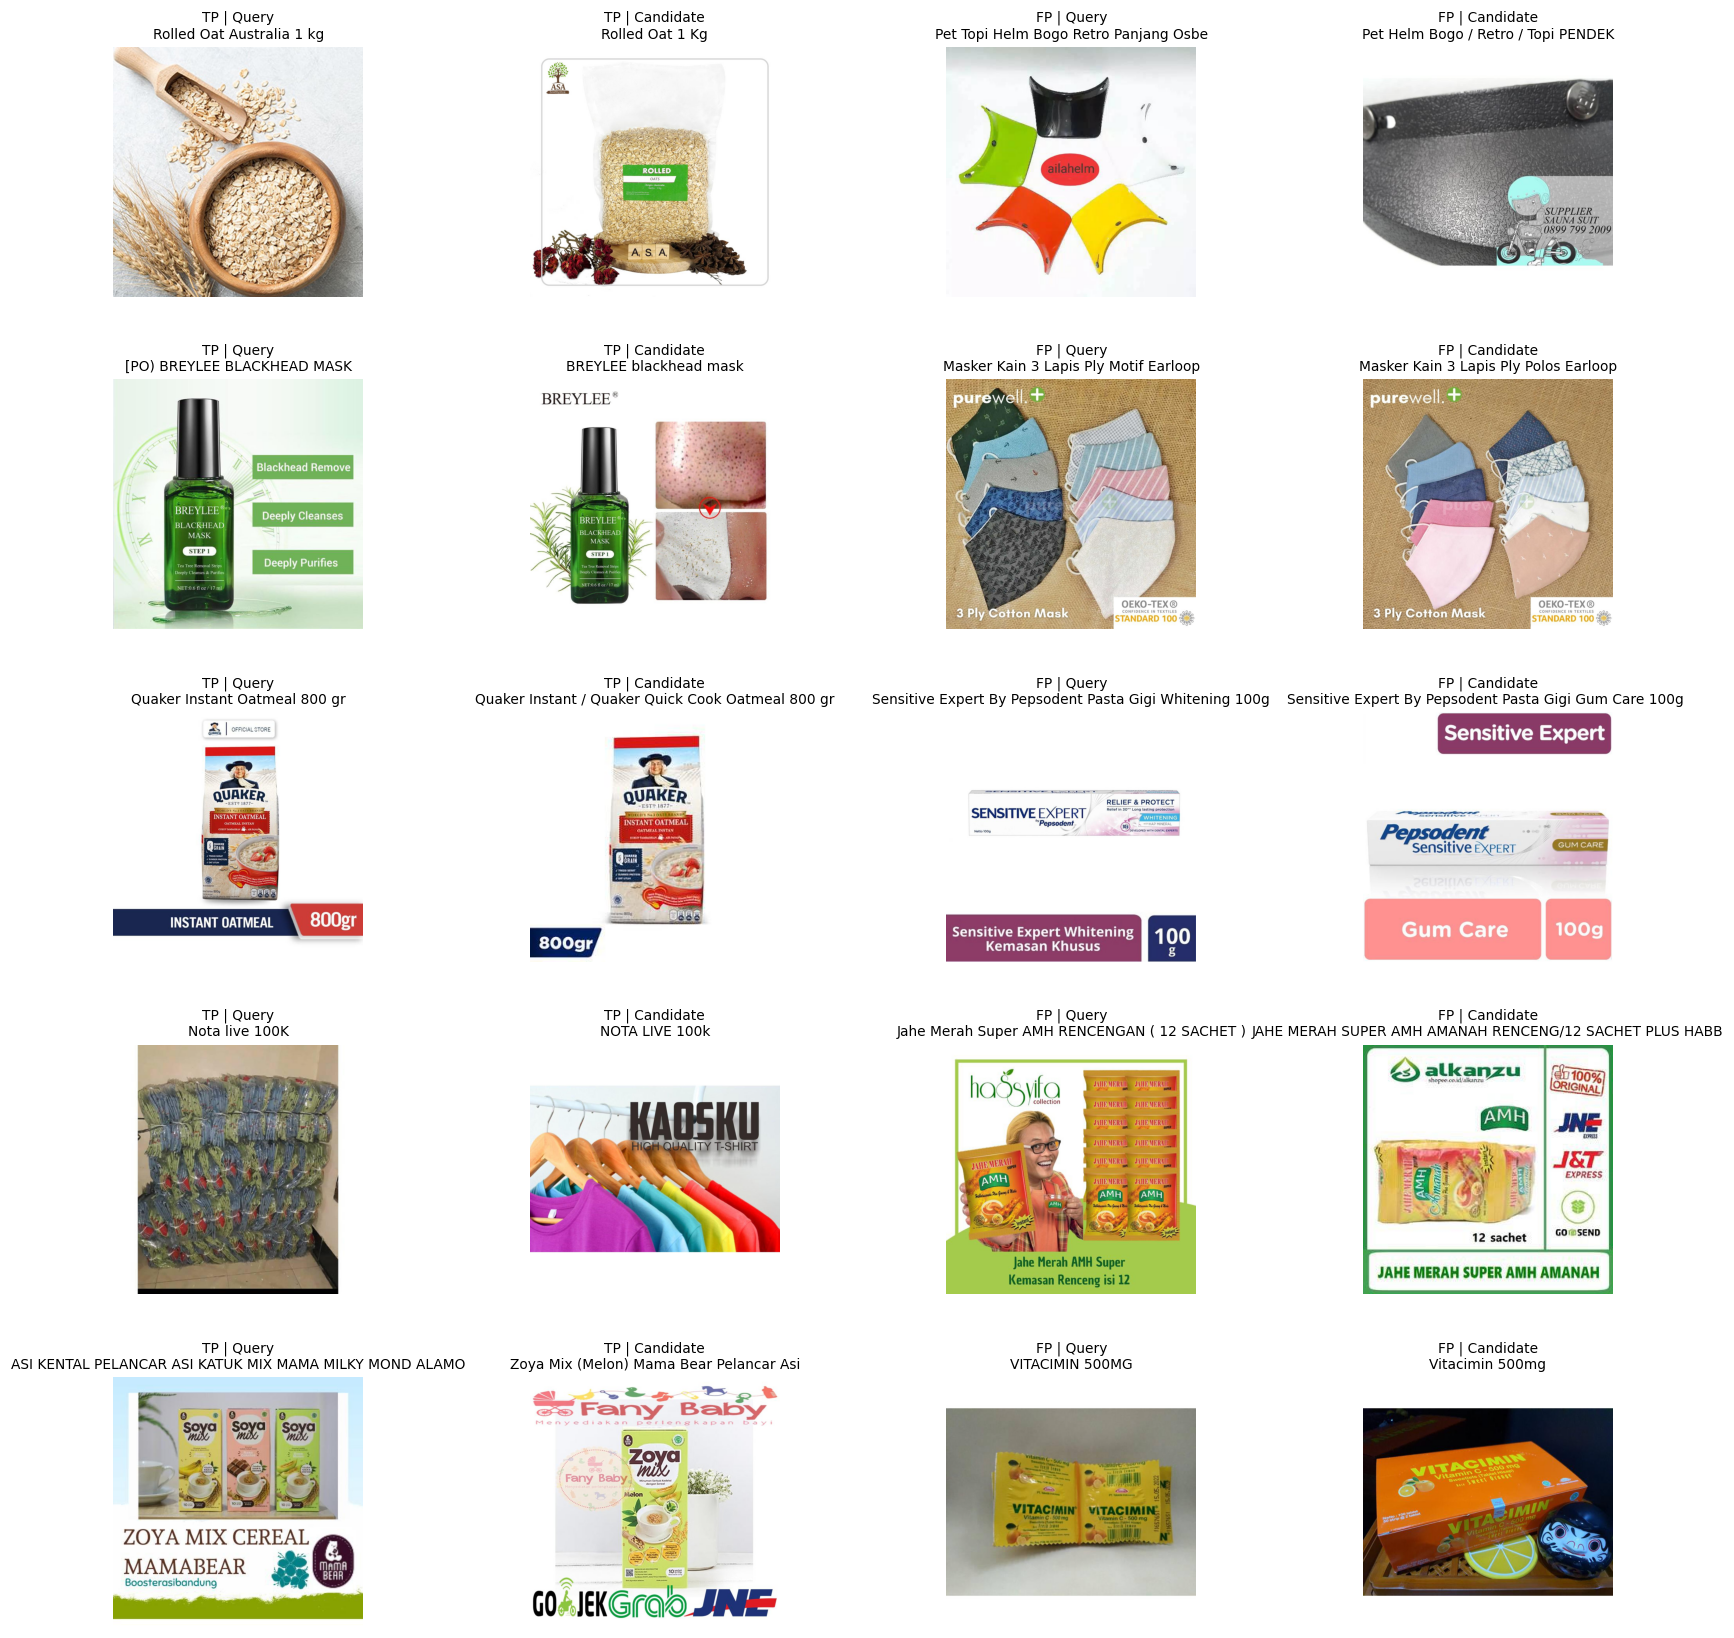

In [22]:
show_pairs(candidates_df, full_df, train_images_path)

In [23]:
from sklearn.metrics.pairwise import cosine_distances

train_id2emb_img = {}
val_id2emb_img = {}

for id, emb in zip(train_img_emb['posting_ids'], train_img_emb['embeddings']):
  train_id2emb_img[id] = emb

for id, emb in zip(val_img_emb['posting_ids'], val_img_emb['embeddings']):
  val_id2emb_img[id] = emb


train_id2emb_text = {}
val_id2emb_text = {}

for id, emb in zip(train_txt_emb['posting_ids'], train_txt_emb['embeddings']):
  train_id2emb_text[id] = emb

for id, emb in zip(val_txt_emb['posting_ids'], val_txt_emb['embeddings']):
  val_id2emb_text[id] = emb

In [24]:
tp_txt_cos_dist = []
tp_img_cos_dist = []

for q_id, cand_id in zip(candidates_df.query_id.values[:5], candidates_df.candidate_id.values[:5]):
  tp_txt_cos_dist.append(cosine_distances(
      val_id2emb_text[q_id].reshape(1, -1),
      val_id2emb_text[cand_id].reshape(1, -1))[0, 0])

for q_id, cand_id in zip(candidates_df.query_id.values[:5], candidates_df.candidate_id.values[:5]):
  tp_img_cos_dist.append(cosine_distances(
      val_id2emb_img[q_id].reshape(1, -1),
      val_id2emb_img[cand_id].reshape(1, -1))[0, 0])


In [25]:
fp_txt_cos_dist = []
fp_img_cos_dist = []

for q_id, cand_id in zip(candidates_df.query_id.values[5:], candidates_df.candidate_id.values[5:]):
  if cand_id in val_id2emb_text:
    cand_emb = val_id2emb_text[cand_id]
  else:
    cand_emb = train_id2emb_text[cand_id]
  fp_txt_cos_dist.append(cosine_distances(
      val_id2emb_text[q_id].reshape(1, -1),
      cand_emb.reshape(1, -1))[0, 0])

for q_id, cand_id in zip(candidates_df.query_id.values[5:], candidates_df.candidate_id.values[5:]):
  if cand_id in val_id2emb_img:
    cand_emb = val_id2emb_img[cand_id]
  else:
    cand_emb = train_id2emb_img[cand_id]
  fp_img_cos_dist.append(cosine_distances(
      val_id2emb_img[q_id].reshape(1, -1),
      cand_emb.reshape(1, -1))[0, 0])


The selected TP and FP pairs show that TF-IDF and EfficientNet make different types of mistakes.

TF-IDF can find correct matches even when the images look very different. However, similar titles can also lead to false positives because the model may miss important differences between products.

EfficientNet helps filter out these incorrect matches, but it can also miss correct ones. This may happen because of different backgrounds, angles, image scales, or the selected distance threshold.

Some false positives have relatively small distances in both modalities. This means that changing the thresholds may help find more correct matches, but it could also increase the number of false positives.

Next, we will compare the distance distributions of all TP and FP pairs to test these assumptions.


In [26]:
print(f"{'Pair':<8} {'Text Distance':<18} {'Image Distance':<18}")
print("-" * 44)

for i, (txt, img) in enumerate(zip(tp_txt_cos_dist, tp_img_cos_dist), start=1):
    print(f"TP {i:<5} {txt:<18.4f} {img:<18.4f}")

Pair     Text Distance      Image Distance    
--------------------------------------------
TP 1     0.0000             0.6727            
TP 2     0.1740             0.2912            
TP 3     0.2174             0.1626            
TP 4     0.0000             0.7331            
TP 5     0.2180             0.2679            


In [27]:
print(f"{'Pair':<8} {'Text Distance':<18} {'Image Distance':<18}")
print("-" * 44)

for i, (txt, img) in enumerate(zip(fp_txt_cos_dist, fp_img_cos_dist), start=1):
    print(f"FP {i:<5} {txt:<18.4f} {img:<18.4f}")

Pair     Text Distance      Image Distance    
--------------------------------------------
FP 1     0.2759             0.6888            
FP 2     0.1479             0.2155            
FP 3     0.0868             0.2118            
FP 4     0.2209             0.3898            
FP 5     0.0000             0.6299            


In [28]:
rows = []
for q_id in true_positive:
  for c_id in true_positive[q_id]:

    query_img_emb = val_id2emb_img[q_id]
    cand_img_emb = val_id2emb_img[c_id]
    query_txt_emb = val_id2emb_text[q_id]
    cand_txt_emb = val_id2emb_text[c_id]

    img_cos_dist = cosine_distances(query_img_emb.reshape(1, -1), cand_img_emb.reshape(1, -1))[0, 0]
    txt_cos_dist = cosine_distances(query_txt_emb.reshape(1, -1), cand_txt_emb.reshape(1, -1))[0, 0]

    rows.append({
        'query_id': q_id,
        'candidate_id': c_id,
        'match_type': 'tp',
        'img_cos_dist': img_cos_dist,
        'txt_cos_dist': txt_cos_dist
    })

for q_id in false_positive:
  for c_id in false_positive[q_id]:

    if c_id in train_id2emb_text:
      cand_txt_emb = train_id2emb_text[c_id]
    else:
      cand_txt_emb = val_id2emb_text[c_id]

    if c_id in train_id2emb_img:
      cand_img_emb = train_id2emb_img[c_id]
    else:
      cand_img_emb = val_id2emb_img[c_id]

    query_img_emb = val_id2emb_img[q_id]
    query_txt_emb = val_id2emb_text[q_id]

    img_cos_dist = cosine_distances(query_img_emb.reshape(1, -1), cand_img_emb.reshape(1, -1))[0, 0]
    txt_cos_dist = cosine_distances(query_txt_emb.reshape(1, -1), cand_txt_emb.reshape(1, -1))[0, 0]

    rows.append({
        'query_id': q_id,
        'candidate_id': c_id,
        'match_type': 'fp',
        'img_cos_dist': img_cos_dist,
        'txt_cos_dist': txt_cos_dist
    })

In [29]:
error_analysis_df = pd.DataFrame(rows)
error_analysis_df.head(2)

,query_id,candidate_id,match_type,img_cos_dist,txt_cos_dist
0,train_1806152124,train_3227306976,tp,0.468440,0.138791
1,train_3054371232,train_2301578474,tp,0.321362,0.060891



We compared cosine distance distributions for 4,256 True Positive and 3,572 False Positive pairs found by TF-IDF but missed by EfficientNet.

**Image distance:**

We noticed that correct matches usually have smaller image distances than incorrect matches. This means EfficientNet can still recognize some similarities between the same products, even when the distance is above our threshold of 0.16.

For example, a correct pair may have an image distance of 0.25, while an incorrect pair has a distance of 0.65. Both pairs are rejected by the image threshold, but the correct pair is still closer in the embedding space.

However, some correct pairs also have very large image distances. So the threshold is not always the only problem. Sometimes EfficientNet struggles to match different images of the same product.

**Text distance:**

Correct matches usually have smaller text distances, while incorrect matches are more common near our threshold of 0.28.

This shows that TF-IDF can find many correct matches using product titles, but it can also consider different products too similar. Even a very small text distance does not always mean that two products are the same.

**Overall conclusion:**

Both models provide useful information, but both make mistakes. Right now, we simply combine their predictions: if either model finds a match, we include it in the final result.

In future experiments, we could try using both distances together. For example, TF-IDF could find a possible match, and the image distance could help us check it.



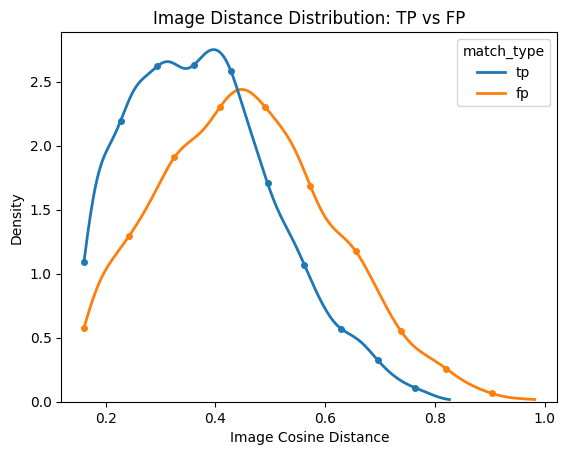

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.kdeplot(
    data=error_analysis_df,
    x='img_cos_dist',
    hue='match_type',
    common_norm=False,
    linewidth=2,
    cut=0
)
for line in ax.lines:
    line.set_marker('o')
    line.set_markevery(20)
    line.set_markersize(4)
plt.xlabel('Image Cosine Distance')
plt.ylabel('Density')
plt.title('Image Distance Distribution: TP vs FP')
plt.show()

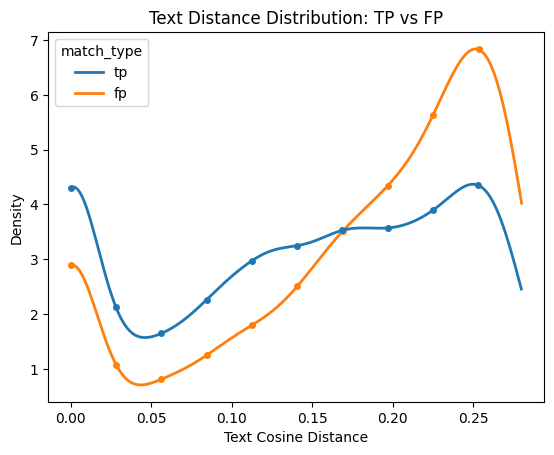

In [31]:
ax = sns.kdeplot(
    data=error_analysis_df,
    x='txt_cos_dist',
    hue='match_type',
    common_norm=False,
    linewidth=2,
    cut=0
)
for line in ax.lines:
    line.set_marker('o')
    line.set_markevery(20)
    line.set_markersize(4)
plt.xlabel('Text Cosine Distance')
plt.ylabel('Density')
plt.title('Text Distance Distribution: TP vs FP')
plt.show()